In [3]:
import torch
import torch.nn as nn
from d2l import torch as d2l

### Batch Normalization
Batch Normalization is a technique that normalizes the inputs to a layer by subtracting the mean and dividing by the standard deviation of the inputs. This mean and standard deviation are calculated for the current batch. The normalized inputs are then scaled and shifted by learnable parameters (Gamma and Beta).

Benefits of Batch Normalization are:

- Improves model performance by reducing internal covariate shift.
- Since inputs are normalized based on batch statistics, Batch Normalization helps in introducing noise in network which help in avoiding overfitting.
- Helps in faster covergence of the model.

Typically batch size of 50-100 is used since it injects approriate noise in the network and helps in avoiding overfitting.

NOTE - Batch Normalization works differently in training and inference mode.
In training the inputs are normalized using the batch statistics. However during inference, the inputs are normalized using the running statistics/running average which are calculated during training.

For convolutional layers, the mean and variance are calculated for each channel. For fully connected layers, the mean and variance are calculated for each feature.

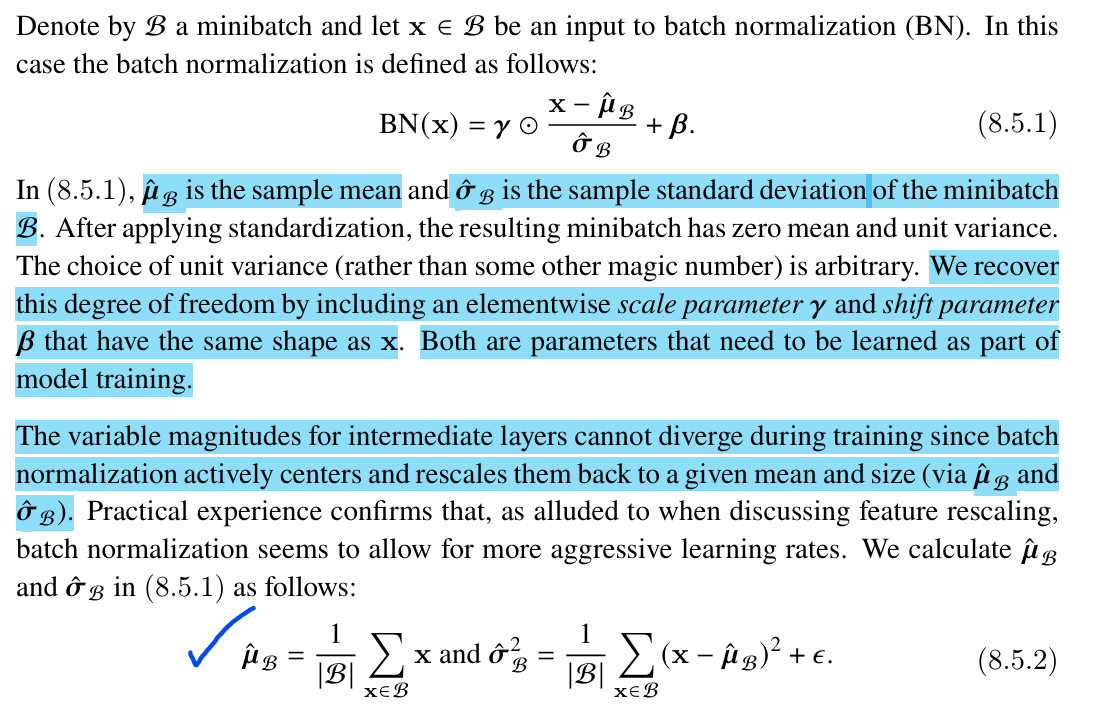


In [1]:
## Implementation of Batch Norm from scratch

def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    if not torch.is_grad_enabled():
        X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
    else:
        assert len(X.shape) in (2, 4)
        ## For fully connected layers
        if len(X.shape) == 2:
            mean = X.mean(dim=0)
            var = ((X - mean) ** 2).mean(dim=0)
        ## For convolutional layers
        else:
            mean = X.mean(dim=[0, 2, 3], keepdim=True)
            var = ((X - mean) ** 2).mean(dim=[0, 2, 3], keepdim=True)
        X_hat = (X - mean) / torch.sqrt(var + eps)
        moving_mean = momentum * moving_mean + (1.0 - momentum) * mean
        moving_var = momentum * moving_var + (1.0 - momentum) * var
    Y = gamma * X_hat + beta  # Scale and shift
    return Y, moving_mean, moving_var

In [4]:
class BatchNorm(nn.Module):

    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2:
            shape = (1, num_features)
        else:
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape))
        self.beta = nn.Parameter(torch.zeros(shape))
        self.moving_mean = torch.zeros(shape)
        self.moving_var = torch.ones(shape)

    def forward(self, X):
        if self.moving_mean.device != X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)
        Y, self.moving_mean, self.moving_var = batch_norm(
            X, self.gamma, self.beta, self.moving_mean,
            self.moving_var, eps=1e-5, momentum=0.1)
        return Y

In [6]:
## Using BN on LeNet

class BNLeNet(d2l.Classifier):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(
            nn.LazyConv2d(6, kernel_size=5),
            BatchNorm(6, num_dims=4),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.LazyConv2d(16, kernel_size=5),
            BatchNorm(16, num_dims=4),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Flatten(),
            nn.LazyLinear(120),
            BatchNorm(120, num_dims=2),
            nn.Sigmoid(),
            nn.LazyLinear(84),
            BatchNorm(84, num_dims=2),
            nn.Sigmoid(),
            nn.LazyLinear(num_classes)
        )


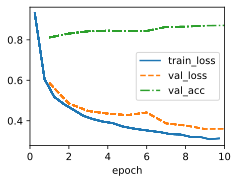

In [7]:
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = BNLeNet(lr=0.1)
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

##### Should we remove bais parameter from FC layer or Conv layer before the Batch Normalization? Why?

Yes, we can remove the bias parameter from any Convolutional or Fully Connected layer that immediately precedes a Batch Normalization layer.Here is the mathematical breakdown of why the original bias becomes completely redundant:The Cancellation Effect: A standard linear or convolutional layer computes $z = Wx + b$. The very first step of Batch Normalization is subtracting the mean ($\mu_B$) of the batch. Because the mean of $Wx + b$ is exactly $\mu_{Wx} + b$, the subtraction step cancels the original bias out entirely:$$(Wx + b) - (\mu_{Wx} + b) = Wx - \mu_{Wx}$$The Replacement: While the original bias $b$ is destroyed, the network still needs the ability to shift the activation. This role is completely taken over by the learnable shift parameter ($\beta$) built directly into the Batch Normalization layer itself.Practical Impact: Leaving the bias parameter in the preceding layer does not mathematically harm the network, but it wastes GPU memory to store the redundant gradients and wastes compute to update a parameter that has absolutely zero effect on the output.

100%|██████████| 26.4M/26.4M [00:06<00:00, 4.17MB/s]


Extracting ./data\FashionMNIST\raw\train-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 216kB/s]


Extracting ./data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 4.42M/4.42M [00:01<00:00, 2.31MB/s]


Extracting ./data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 1.74MB/s]


Extracting ./data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw

Running Experiment 1: Plotting Validation Accuracy (LR=0.1)...


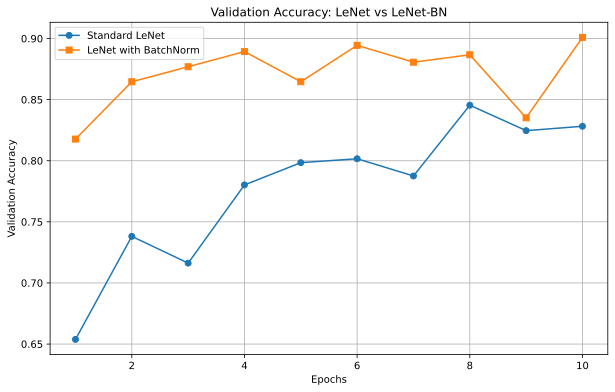


Running Experiment 2: Maximum Learning Rate Sweep...
Standard LeNet Failed at LR = 1.0 (Accuracy: 10.00%)
LeNet with BatchNorm Failed at LR = 10.0 (Accuracy: 10.00%)
------------------------------
Max Stable LR for Standard LeNet: 0.5
Max Stable LR for LeNet with BN:  5.0


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# ==========================================
# 1. Architecture Definitions
# ==========================================
class LeNetStandard(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.net(x)

class LeNetBatchNorm(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # bias=False is crucial here to save memory, as BN handles the shift
            nn.Conv2d(1, 6, kernel_size=5, padding=2, bias=False), 
            nn.BatchNorm2d(6), nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            
            nn.Conv2d(6, 16, kernel_size=5, bias=False), 
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120, bias=False), 
            nn.BatchNorm1d(120), nn.ReLU(),
            
            nn.Linear(120, 84, bias=False), 
            nn.BatchNorm1d(84), nn.ReLU(),
            
            nn.Linear(84, 10) # No BN on the final output logits
        )

    def forward(self, x):
        return self.net(x)

# ==========================================
# 2. Data & Training Engine
# ==========================================
def get_dataloader(batch_size=256):
    transform = transforms.Compose([transforms.ToTensor()])
    # Using FashionMNIST as it is a standard drop-in for 28x28 grayscale testing
    trainset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
    testset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
    
    trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
    testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)
    return trainloader, testloader

def train_and_validate(model, trainloader, testloader, lr, epochs, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    val_accuracies = []
    
    for epoch in range(epochs):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
        # Validation Phase
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                
        val_acc = correct / total
        val_accuracies.append(val_acc)
        
    return val_accuracies

# ==========================================
# 3. Experimental Execution
# ==========================================
def experiment_1_plot_accuracy(device, trainloader, testloader):
    print("Running Experiment 1: Plotting Validation Accuracy (LR=0.1)...")
    epochs = 10
    lr = 0.1
    
    model_std = LeNetStandard().to(device)
    acc_std = train_and_validate(model_std, trainloader, testloader, lr, epochs, device)
    
    model_bn = LeNetBatchNorm().to(device)
    acc_bn = train_and_validate(model_bn, trainloader, testloader, lr, epochs, device)
    
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, epochs+1), acc_std, label='Standard LeNet', marker='o')
    plt.plot(range(1, epochs+1), acc_bn, label='LeNet with BatchNorm', marker='s')
    plt.xlabel('Epochs')
    plt.ylabel('Validation Accuracy')
    plt.title('Validation Accuracy: LeNet vs LeNet-BN')
    plt.legend()
    plt.grid(True)
    plt.show()

def experiment_2_find_max_lr(device, trainloader, testloader):
    print("\nRunning Experiment 2: Maximum Learning Rate Sweep...")
    
    # We test exponentially increasing learning rates
    learning_rates = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0]
    
    def test_max_lr(model_class, name):
        max_successful_lr = None
        for lr in learning_rates:
            model = model_class().to(device)
            # Run for just 2 epochs to see if it immediately diverges
            acc = train_and_validate(model, trainloader, testloader, lr, epochs=2, device=device)
            
            # If accuracy is ~10% (random guess for 10 classes) or drops to NaN, it failed
            final_acc = acc[-1]
            if final_acc <= 0.15:
                print(f"{name} Failed at LR = {lr} (Accuracy: {final_acc:.2%})")
                break
            else:
                max_successful_lr = lr
                
        return max_successful_lr

    max_lr_std = test_max_lr(LeNetStandard, "Standard LeNet")
    max_lr_bn = test_max_lr(LeNetBatchNorm, "LeNet with BatchNorm")
    
    print("-" * 30)
    print(f"Max Stable LR for Standard LeNet: {max_lr_std}")
    print(f"Max Stable LR for LeNet with BN:  {max_lr_bn}")

if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    trainloader, testloader = get_dataloader()
    
    experiment_1_plot_accuracy(device, trainloader, testloader)
    experiment_2_find_max_lr(device, trainloader, testloader)